# 07 · Escenarios hipotéticos (Fase 10)
Se cambia **una** circunstancia en las personas que nacieron en Q1 y se observa cómo cambia la probabilidad media que predice el modelo.

> ⚠️ Son simulaciones del modelo: describen **asociaciones**, no lo que pasaría si una política cambiara esa circunstancia.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import display, Markdown
pd.set_option("display.max_columns", 30)
from src.config import *
df = pd.read_parquet(PROCESSED / "emovi_movilidad.parquet")
q1 = df[df.sigue_q1.notna()]
from src.models import train as T
tr, te = T.split(df)
tabla, modelos = T.compare(tr, te, T.NUM, T.CAT)
elegido, mejor_auc = T.choose(tabla)
modelo = modelos[elegido]
from src.evaluation import interpret as I
from src.visualization import plots as V
import matplotlib.pyplot as plt

,Escenario,Personas afectadas,Prob. media de seguir en Q1,Cambio (puntos %)
0,Situación observada,2674,0.517,0.000
1,Madre con secundaria (en vez de primaria o menos),2139,0.496,-1.953
2,Crecer en ciudad mediana (en vez de pueblo),1802,0.479,-7.390
3,Crecer en el Norte (en vez del Sur),1355,0.424,-20.943
4,Tono de piel claro (en vez de oscuro),578,0.538,1.500


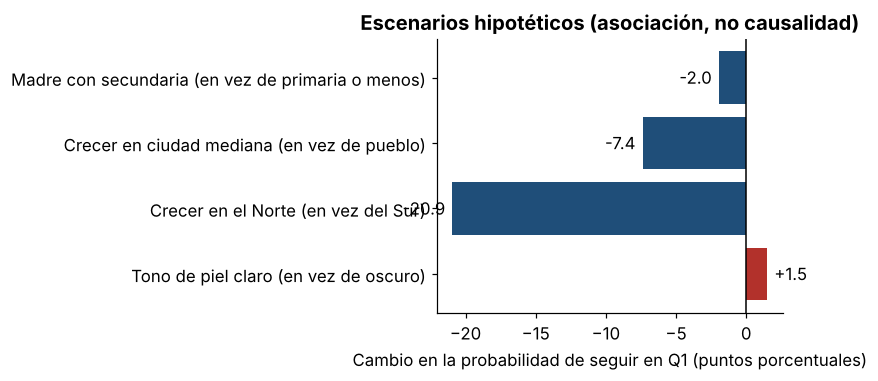

In [2]:
esc = I.scenarios(modelo, q1, T.NUM, T.CAT)
esc.to_csv(TABLES / "escenarios.csv", index=False); display(esc); V.escenarios(esc); plt.show()

**Lectura:** el escenario con mayor asociación es haber crecido en el Norte en vez del Sur (≈ −21 puntos). Le sigue crecer en una ciudad mediana en vez de un pueblo (≈ −7 puntos). Esto sugiere que la **geografía de oportunidades** (mercados laborales y servicios) pesa más que las características del hogar.

El escenario de la madre con secundaria cambia poco (≈ −2 puntos), porque dentro del 20% más pobre casi nadie tiene una madre con más escolaridad: el modelo tiene poca información para aprender ese efecto. El escenario de tono de piel da +1.5 puntos, una cifra pequeña y no significativa en el modelo explicativo. La brecha por tono que aparece en la descripción (56% vs 49%) se explica en buena parte por la región y la lengua.